# Import required Libraries

In [96]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


# Read Dataset

In [2]:
df=pd.read_csv(r"..\datasets\diabetes.csv")

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Checking Null Value

In [5]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [6]:
df.shape

(768, 9)

In [13]:
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [17]:
(df["Outcome"] == 1).sum()

268

Separate label and Data

In [19]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [20]:
data=df.iloc[:,:-1]
label=df.iloc[:,-1]

In [22]:
data.shape

(768, 8)

In [23]:
label

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

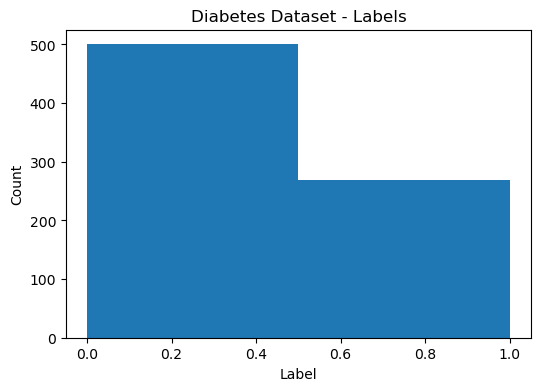

In [ ]:
# Visualize the labels
# plt.figure(figsize=(6, 4))
plt.hist(label, bins=2)
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Diabetes Dataset - Labels')
plt.show()

In [24]:
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


Standarize the Data 

In [25]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


In [33]:
data["Insulin"].max()

846

In [34]:
scale=StandardScaler()

In [35]:
scale.fit(data)

,copy,True
,with_mean,True
,with_std,True


In [36]:
x=scale.transform(data)
y=df.iloc[:,-1]

In [41]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


In [40]:
x[0]

array([ 0.63994726,  0.84832379,  0.14964075,  0.90726993, -0.69289057,
        0.20401277,  0.46849198,  1.4259954 ])

In [44]:
x.max(axis=0)

array([3.90657835, 2.44447821, 2.73452825, 4.92186584, 6.65283938,
       4.45580749, 5.88356477, 4.06371575])

In [60]:
np.random.seed(43)
l = [10, 20, 30]
np.random.shuffle(l)

l

[20, 30, 10]

Splitting Data For training And Validation

In [61]:
xtrain,xtest,ytrain,ytest = train_test_split(x,label,test_size=0.2, random_state=2)

In [62]:
xtrain

array([[-0.84488505,  0.09719231,  0.25303625, ..., -0.53211885,
        -1.12311057, -0.27575966],
       [-0.84488505, -0.81042491,  0.66661825, ...,  0.38169971,
        -0.72143478,  0.83038113],
       [-1.14185152, -0.84172205,  0.04624525, ...,  1.4605133 ,
        -0.37714125, -1.04154944],
       ...,
       [ 0.04601433,  0.12848945,  0.04624525, ..., -0.39250768,
         2.02989333,  1.00055664],
       [-0.25095213, -0.15318486,  0.25303625, ..., -0.72249772,
        -1.10196973, -0.78628618],
       [ 0.04601433, -0.34096773, -0.16054575, ..., -0.01174995,
        -0.00264654, -0.36084741]])

In [14]:
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [65]:
xtrain.shape

(614, 8)

In [67]:
ytrain.shape

(614,)

In [69]:
xtest.shape

(154, 8)

In [71]:
ytest.shape

(154,)

# Create a logistic regression model

In [72]:
model=LogisticRegression()

# Fit the logistic regression model to the training data

In [73]:
model.fit(xtrain,ytrain)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


# Make Prediction on unseen data

In [74]:
prediction=model.predict(xtest)

In [76]:
ytest.iloc[0:5]

158    0
251    0
631    0
757    1
689    1
Name: Outcome, dtype: int64

In [77]:
prediction[0:5]

array([0, 0, 0, 0, 1], dtype=int64)

In [81]:
len(ytest)

154

In [82]:
sum(ytest == prediction)/len(ytest)   * 100

76.62337662337663

In [86]:
pred_xtrain = model.predict(xtrain)

In [87]:
pred_xtrain.shape

(614,)

In [88]:
ytrain.shape

(614,)

In [90]:
sum(ytrain == pred_xtrain)/614   * 100

78.0130293159609

# Confusion Matrix

In [91]:
from sklearn.metrics import confusion_matrix, accuracy_score

In [93]:
acc = accuracy_score(ytest, prediction)
acc

0.7662337662337663

In [94]:

cm = confusion_matrix(ytest, prediction)
print(cm)

[[96 13]
 [23 22]]


Text(50.722222222222214, 0.5, 'Actual')

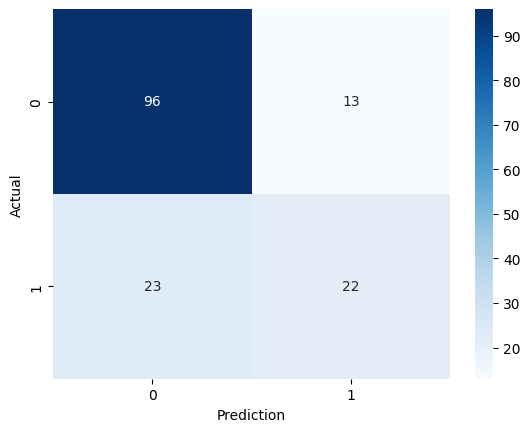

In [102]:
sns.heatmap(cm, cmap='Blues', annot=True)
plt.xlabel("Prediction")
plt.ylabel("Actual")

# checking the result On Unseen Data

In [103]:

input=(3,126,88,41,235,39.3,0.704,27)
len(input)

8

In [104]:
input_array=np.asarray(input)

In [105]:
input_reshape=input_array.reshape(1,-1)

In [106]:
data=scale.transform(input_reshape)

c:\Users\Abbas\anaconda3\envs\imageenv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [107]:
print(data)

[[-0.25095213  0.1597866   0.97680475  1.28363829  1.34758997  0.92745247
   0.70104112 -0.53102292]]


In [108]:
prediction=model.predict(data)
print(prediction)
if(prediction[0]==1):
    print("This patient have Diabetics",prediction)
else:
    print("no diabetics",prediction)

[0]
no diabetics [0]


In [111]:
model.predict(data, logit=True)

TypeError: LinearClassifierMixin.predict() got an unexpected keyword argument 'logit'

In [114]:
model.predict_proba(data)

array([[0.58357279, 0.41642721]])

In [116]:
prob_xtest = model.predict_proba(xtest)

In [117]:
prob_xtest.shape

(154, 2)

In [118]:
prob_xtest.argmax(axis=1)

array([0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0],
      dtype=int64)

In [119]:
prob_xtest

array([[0.94990855, 0.05009145],
       [0.82535183, 0.17464817],
       [0.90663831, 0.09336169],
       [0.74566788, 0.25433212],
       [0.37159197, 0.62840803],
       [0.88403696, 0.11596304],
       [0.93302816, 0.06697184],
       [0.58236028, 0.41763972],
       [0.95039509, 0.04960491],
       [0.43307433, 0.56692567],
       [0.65323643, 0.34676357],
       [0.59026995, 0.40973005],
       [0.30248528, 0.69751472],
       [0.80178852, 0.19821148],
       [0.97855411, 0.02144589],
       [0.17408172, 0.82591828],
       [0.14205851, 0.85794149],
       [0.96805702, 0.03194298],
       [0.74911804, 0.25088196],
       [0.10695598, 0.89304402],
       [0.04683786, 0.95316214],
       [0.17033177, 0.82966823],
       [0.88360686, 0.11639314],
       [0.55899651, 0.44100349],
       [0.90998871, 0.09001129],
       [0.93118659, 0.06881341],
       [0.35562894, 0.64437106],
       [0.58357279, 0.41642721],
       [0.82324675, 0.17675325],
       [0.71705217, 0.28294783],
       [0.

In [ ]:
import joblib

# Save the trained model and scaler together
model_data = {
    "model": model,
    "scaler": scale,
    "feature_names": [
        "Pregnancies",
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI",
        "DiabetesPedigreeFunction",
        "Age"
    ]
}

joblib.dump(model_data, "diabetes_model.pkl")

print("Model saved successfully!")